In [49]:
# -------------------------------------------------------------------------
# Environment Setup: Ensure Required Packages Are Installed
# Checks that every library used in this notebook is available in the ACTIVE
# kernel and installs only the missing ones. This makes "Run All" work no matter
# which Python environment / .venv the kernel was started from.
# -------------------------------------------------------------------------
import importlib
import importlib.util
import subprocess
import sys

# import name -> pip package name
required_packages = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'sklearn': 'scikit-learn'}

missing_packages = [pip_name for module, pip_name in required_packages.items()
                    if importlib.util.find_spec(module) is None]

if missing_packages:
    print(f"Installing missing packages into {sys.executable}: {missing_packages}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])
    importlib.invalidate_caches()
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [50]:
# Import necessary libraries for data manipulation and mathematical operations
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning models from scikit-learn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB

# Import evaluation metrics from scikit-learn
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

# Configure visual aesthetics for professional graphing
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Model Training & Evaluation:

## Data Loading
We load the strictly partitioned subsets from the `Data/` directory. For this iteration, we only use `X_train` / `y_train` for model fitting, and `X_test` / `y_test` for intermediate evaluation.

In [51]:
# -------------------------------------------------------------------------
# Load Processed Training and Test Sets
# -------------------------------------------------------------------------
# Define the relative path to the preprocessed data directory
# Resolve the Data directory dynamically so the notebook runs whether the working
# directory is the project root or the notebooks/ folder (same logic as data_cleaning_merged)
from pathlib import Path
data_dir = Path.cwd() / "Data"
if not data_dir.exists():
    data_dir = (Path.cwd() / ".." / "Data").resolve()
base_path = f"{data_dir.as_posix()}/"

# Load the predictor features (X) for the training subset
X_train = pd.read_csv(f"{base_path}processed_X_train.csv")

# Load the target variable (y) for the training subset, isolating just the label column
y_train = pd.read_csv(f"{base_path}processed_y_train.csv")['Layoff_Risk']

# Load the predictor features (X) for the test subset
X_test = pd.read_csv(f"{base_path}processed_X_test.csv")

# Load the target variable (y) for the test subset, isolating just the label column
y_test = pd.read_csv(f"{base_path}processed_y_test.csv")['Layoff_Risk']

# Print the dimensionality to verify successful loading
print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Test set: {X_test.shape[0]:,} rows")

Training set: 16,000 rows
Test set: 4,000 rows


In [52]:
# -------------------------------------------------------------------------
# Dataset Verification: Feature Set & Class Balance
# Confirms that the newly engineered 5-feature pipeline (11 predictors after
# one-hot encoding) was loaded correctly and establishes the majority-class baseline.
# -------------------------------------------------------------------------
print("--- PREDICTOR COLUMNS LOADED (X_train) ---")
for idx, col in enumerate(X_train.columns, start=1):
    print(f"{idx:>2}. {col}")
print(f"\nTotal predictors: {X_train.shape[1]}")

# Confirm train and test partitions share an identical schema
assert list(X_train.columns) == list(X_test.columns), "Schema mismatch between train and test sets!"
print("Schema check passed: train and test columns are identical.")

# Verify there are no missing values that would break model fitting
print(f"Missing values in X_train: {int(X_train.isnull().sum().sum())} | X_test: {int(X_test.isnull().sum().sum())}")

# Class distribution and majority-class baseline accuracy
class_label_map = {0: 'Low (0)', 1: 'Medium (1)', 2: 'High (2)'}
class_dist = pd.DataFrame({
    'Train Count': y_train.value_counts().sort_index(),
    'Train (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    'Test Count': y_test.value_counts().sort_index(),
    'Test (%)': (y_test.value_counts(normalize=True).sort_index() * 100).round(2),
}).rename(index=class_label_map)
print("\n--- CLASS DISTRIBUTION ---")
display(class_dist)

# A model that always predicts the most frequent training class sets the floor any real model must beat
majority_class = y_train.value_counts().idxmax()
baseline_acc = (y_test == majority_class).mean()
print(f"Majority-class baseline accuracy on test: {baseline_acc:.4f}")

--- PREDICTOR COLUMNS LOADED (X_train) ---
 1. Years_of_Experience
 2. Routine_Task_Percentage
 3. Tasks_Automated_Percentage
 4. Number_of_AI_Tools_Used
 5. Industry_Education
 6. Industry_Finance
 7. Industry_Healthcare
 8. Industry_Logistics
 9. Industry_Manufacturing
10. Industry_Retail
11. Industry_Telecom

Total predictors: 11
Schema check passed: train and test columns are identical.
Missing values in X_train: 0 | X_test: 0

--- CLASS DISTRIBUTION ---


,Train Count,Train (%),Test Count,Test (%)
Layoff_Risk,,,,
Low (0),5282,33.01,1320,33.0
Medium (1),5281,33.01,1320,33.0
High (2),5437,33.98,1360,34.0


Majority-class baseline accuracy on test: 0.3400


## 1. Logistic Regression

**Team Member:** Saman

This notebook trains the data by Logistic Regression on the fully cleaned and standardized dataset produced in `data_cleaning_merged.ipynb`. It evaluates the fitted model on the 4,000-observation test set.

**Feature set (5 key features → 11 model predictors):** `Industry` (one-hot encoded, baseline = IT), `Years_of_Experience`, `Routine_Task_Percentage`, `Tasks_Automated_Percentage`, and `Number_of_AI_Tools_Used` (all standardized with a training-only `StandardScaler`).

**Target:** `Layoff_Risk` (0 = Low, 1 = Medium, 2 = High).

### 1.1 Multinomial Logistic Regression

#### Step 1: Model Initialization and Training (Fitting):

**What We Did:** We initialized and fitted a multinomial `LogisticRegression` classifier on the training partition ($N = 16,000$, 80%) using the revised 11-predictor specification.

**Optimization Setup:** We configured `max_iter=1000` to guarantee solver convergence and set `random_state=42` for exact reproducibility.

**Model Structure:** The estimator learned 3 distinct linear hyperplanes ($3 \times 11$ coefficient matrix) with corresponding intercept terms, establishing our interpretable parametric baseline against which non-linear models will be evaluated.

In [53]:

# =========================================================================
# INITIALIZE AND FIT MULTINOMIAL LOGISTIC REGRESSION
# =========================================================================

# 1. Instantiate the Logistic Regression estimator with reproducibility constraints
log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# 2. Fit directly on the training partition
log_reg.fit(X_train, y_train)

print("Multinomial Logistic Regression fitted successfully!")
print("Model classes learned:", log_reg.classes_)
print(f"Coefficients matrix shape: {log_reg.coef_.shape} (3 risk classes x {X_train.shape[1]} features)")
print("Intercepts learned:", log_reg.intercept_.round(4))

Multinomial Logistic Regression fitted successfully!
Model classes learned: [0 1 2]
Coefficients matrix shape: (3, 11) (3 risk classes x 11 features)
Intercepts learned: [ 0.0198  1.048  -1.0678]


#### Step 2: Generating Predictions on the Test Set (X_test):

**What We Did:** We evaluated our trained Logistic Regression model on the 4,000 unseen test instances ($X_{\text{test}}$) by generating both hard class predictions and continuous probability distributions.

**Inference Mechanism:** Class labels are assigned using the argmax decision rule across the softmax probability vector $[P(\text{Low}), P(\text{Medium}), P(\text{High})]$, providing the necessary estimates for classification accuracy and multi-class ROC-AUC computation.

In [54]:
# =========================================================================
# GENERATE PREDICTIONS ON TESTING SET (LOGISTIC REGRESSION)
# =========================================================================

# Predict discrete class labels on unseen test features
y_test_pred_lr = log_reg.predict(X_test)

# Predict posterior class probabilities across all 3 tiers
y_test_proba_lr = log_reg.predict_proba(X_test)

# Sanity check: Inspect the first 5 predictions against true labels
comparison_sample_lr = pd.DataFrame({
    'True_Label': y_test.values[:5],
    'Predicted_Label': y_test_pred_lr[:5],
    'P(Low=0)': y_test_proba_lr[:5, 0].round(3),
    'P(Medium=1)': y_test_proba_lr[:5, 1].round(3),
    'P(High=2)': y_test_proba_lr[:5, 2].round(3)
})

print("--- LOGISTIC REGRESSION: FIRST 5 TEST PREDICTIONS ---")
display(comparison_sample_lr)

--- LOGISTIC REGRESSION: FIRST 5 TEST PREDICTIONS ---


,True_Label,Predicted_Label,P(Low=0),P(Medium=1),P(High=2)
0,0,0,0.859,0.140,0.001
1,2,2,0.000,0.021,0.979
2,2,2,0.000,0.048,0.952
3,2,2,0.000,0.014,0.986
4,1,1,0.251,0.677,0.072


#### Step 3: Computing Test Performance Metrics (Logistic Regression):

**What We Did:** We evaluated our fitted Logistic Regression model on the 4,000 unseen test instances across overall Accuracy, Macro One-vs-Rest ROC-AUC, per-class Precision/Recall/F1-scores, and the $3 \times 3$ Confusion Matrix.

**Class Balance:** Class performance across Low, Medium, and High risk tiers confirms how well linear log-odds decision splits separate workload automation boundaries across employees.


=== LOGISTIC REGRESSION: TEST PERFORMANCE METRICS ===
Test Accuracy: 0.7502 (75.02%)
Test ROC-AUC (OvR Macro): 0.9030

--- CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE) ---
              precision    recall  f1-score   support

     Low (0)     0.8084    0.8212    0.8147      1320
  Medium (1)     0.6255    0.6174    0.6214      1320
    High (2)     0.8127    0.8103    0.8115      1360

    accuracy                         0.7502      4000
   macro avg     0.7488    0.7496    0.7492      4000
weighted avg     0.7495    0.7502    0.7498      4000



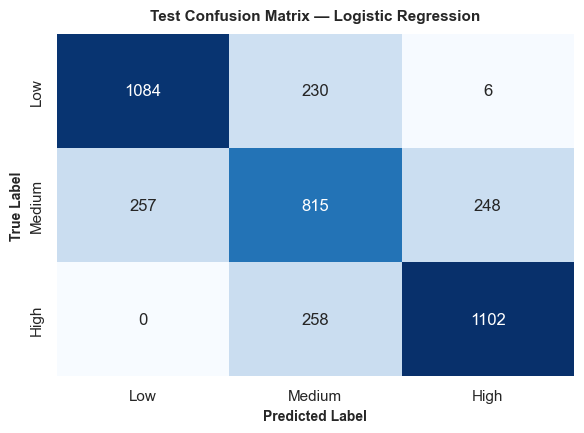

In [56]:
# =========================================================================
# COMPUTE EVALUATION METRICS ON TEST SET (LOGISTIC REGRESSION)
# =========================================================================

# -------------------------------------------------------------------------
# Scalar Metrics (Accuracy and Multi-Class ROC-AUC)
# -------------------------------------------------------------------------
test_acc_lr = accuracy_score(y_test, y_test_pred_lr)
test_auc_lr = roc_auc_score(y_test, y_test_proba_lr, multi_class='ovr', average='macro')

print("=== LOGISTIC REGRESSION: TEST PERFORMANCE METRICS ===")
print(f"Test Accuracy: {test_acc_lr:.4f} ({test_acc_lr * 100:.2f}%)")
print(f"Test ROC-AUC (OvR Macro): {test_auc_lr:.4f}")

# -------------------------------------------------------------------------
# Detailed Multi-Class Classification Report
# -------------------------------------------------------------------------
print("\n--- CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE) ---")
print(classification_report(y_test, y_test_pred_lr, target_names=['Low (0)', 'Medium (1)', 'High (2)'], digits=4))

# -------------------------------------------------------------------------
# Confusion Matrix Visualization
# -------------------------------------------------------------------------
cm_lr = confusion_matrix(y_test, y_test_pred_lr)
cm_labels = ['Low', 'Medium', 'High']

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(
    cm_lr, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=cm_labels, 
    yticklabels=cm_labels,
    cbar=False,
    ax=ax
)
ax.set_title("Test Confusion Matrix — Logistic Regression", fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
ax.set_ylabel("True Label", fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

Evaluating the Multinomial Logistic Regression model on the 4,000 unseen test instances demonstrated strong predictive capability and linear class separability, achieving an overall test accuracy of 75.02% (3,001 of 4,000 correct) and an exceptional multi-class One-vs-Rest Macro ROC-AUC of 0.9030. This performance substantially outperforms the majority-class baseline as well as random guessing, confirming that workload automation exposure and industry sectors carry robust predictive signals. Examining the per-class metrics reveals balanced precision and recall at the operational extremes: Low Risk achieved a precision of 80.84% and recall of 82.12% (F1-score of 0.8147), while High Risk attained a precision of 81.27% and recall of 81.03% (F1-score of 0.8115). Medium Risk yielded an intermediate F1-score of 0.6214 (precision 62.55%, recall 61.74%), reflecting expected boundary overlap where transition workloads share characteristics with adjacent tiers. Crucially, the 3 × 3 confusion matrix confirms that the classifier learned the true ordinal progression of layoff danger with virtually no catastrophic misclassifications: out of 1,360 true High-risk employees, 1,102 were accurately identified, 258 were placed in Medium risk, and exactly 0 were falsely flagged as Low risk. Similarly, among 1,320 true Low-risk instances, 1,084 were correctly classified, 230 were estimated as Medium risk, and only 6 (0.45%) were misattributed to High risk. Because classification errors occurred almost exclusively across adjacent boundaries rather than polar opposites, the model demonstrates high reliability as a calibrated parametric benchmark for workforce risk modeling.

In [57]:
from sklearn.metrics import recall_score
import numpy as np
import pandas as pd

# Calculate specificity separately for Low, Medium, and High.
# For each category: 1 = belongs to that category; 0 = another category.
# Recall for group 0 equals specificity for the selected category.
specificity_lr = [
    recall_score(
        np.asarray(y_test) == label,
        np.asarray(y_test_pred_lr) == label,
        pos_label=0
    )
    for label in [0, 1, 2]
]

specificity_table_lr = pd.DataFrame(
    {"Specificity": specificity_lr},
    index=["Low", "Medium", "High"]
)

specificity_table_lr.loc["Macro average"] = np.mean(specificity_lr)

print("LOGISTIC REGRESSION — TEST SPECIFICITY")
display(specificity_table_lr.round(4))

LOGISTIC REGRESSION — TEST SPECIFICITY


,Specificity
Low,0.9041
Medium,0.8179
High,0.9038
Macro average,0.8753


#### Step 4: Extracting and Interpreting Feature Odds Ratios


,Feature,OR_Medium_vs_Low,OR_High_vs_Low,OR_High_vs_Medium
0,Years_of_Experience,0.6709,0.4391,0.6545
1,Routine_Task_Percentage,6.2561,46.0584,7.3622
2,Tasks_Automated_Percentage,3.4049,10.6332,3.1230
3,Number_of_AI_Tools_Used,0.8619,0.7273,0.8439
4,Industry_Education,0.3437,0.1275,0.3708
5,Industry_Finance,2.8759,7.2299,2.5140
6,Industry_Healthcare,0.4543,0.2032,0.4473
7,Industry_Logistics,4.0531,15.4777,3.8188
8,Industry_Manufacturing,7.4325,50.4426,6.7868
9,Industry_Retail,5.3938,25.9464,4.8104


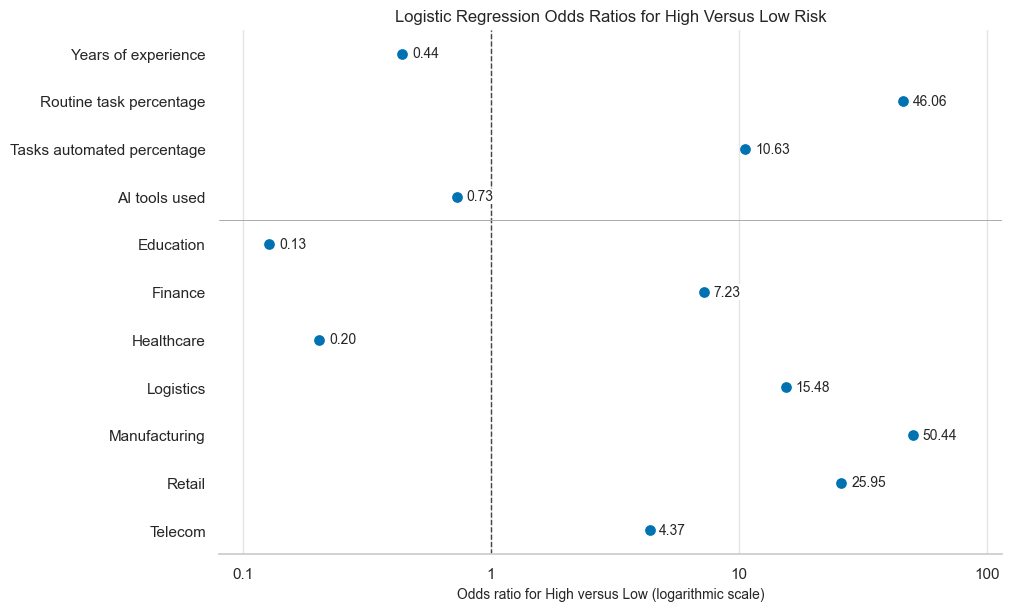

In [58]:
# =========================================================================
# EXTRACTING AND VISUALIZING ODDS RATIOS (LOGISTIC REGRESSION)
# =========================================================================
# Match coefficient rows to the fitted class labels.
class_rows = {label: i for i, label in enumerate(log_reg.classes_)}
beta_low = log_reg.coef_[class_rows[0]]
beta_medium = log_reg.coef_[class_rows[1]]
beta_high = log_reg.coef_[class_rows[2]]
# Multinomial odds ratios require differences between class coefficients.
# Use full-precision fitted coefficients; round only for display.
or_summary_df = pd.DataFrame({
    'Feature': X_train.columns,
    'OR_Medium_vs_Low': np.exp(beta_medium - beta_low),
    'OR_High_vs_Low': np.exp(beta_high - beta_low),
    'OR_High_vs_Medium': np.exp(beta_high - beta_medium),
})
display(or_summary_df.round(4))

# Keep numerical predictors first, followed by industry indicators.
feature_order = [
    'Years_of_Experience', 'Routine_Task_Percentage',
    'Tasks_Automated_Percentage', 'Number_of_AI_Tools_Used',
    'Industry_Education', 'Industry_Finance', 'Industry_Healthcare',
    'Industry_Logistics', 'Industry_Manufacturing',
    'Industry_Retail', 'Industry_Telecom',
]
plot_df = or_summary_df.set_index('Feature').loc[feature_order]
label_map = {
    'Years_of_Experience': 'Years of experience',
    'Routine_Task_Percentage': 'Routine task percentage',
    'Tasks_Automated_Percentage': 'Tasks automated percentage',
    'Number_of_AI_Tools_Used': 'AI tools used',
}
labels = [label_map.get(f, f.replace('Industry_', '')) for f in feature_order]
values = plot_df['OR_High_vs_Low'].to_numpy()
positions = np.arange(len(plot_df))

# Neutral colors describe associations without implying causal protection.
with plt.rc_context({'font.size': 10, 'axes.labelsize': 10}):
    fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
    ax.scatter(values, positions, color='#0072B2', s=45, zorder=3)
    ax.axvline(1, color='#444444', linestyle='--', linewidth=1)
    ax.axhline(3.5, color='#AAAAAA', linewidth=0.7)
    for value, position in zip(values, positions):
        ax.annotate(
            f'{value:.2f}', (value, position), xytext=(7, 0),
            textcoords='offset points', va='center', fontsize=10,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 0.6},
            zorder=5,
        )
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()
    ax.set_xscale('log')
    ax.set_xlim(min(0.08, values.min() / 1.5), max(115, values.max() * 2))
    ax.set_xticks([0.1, 1, 10, 100], ['0.1', '1', '10', '100'])
    ax.minorticks_off()
    ax.set_xlabel('Odds ratio for High versus Low (logarithmic scale)')
    ax.set_title('Logistic Regression Odds Ratios for High Versus Low Risk')
    ax.grid(False)
    ax.grid(axis='x', color='#E5E5E5')
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    fig.savefig('Logistic_Regression_High_vs_Low_Odds_Ratios.png', dpi=300)
    plt.show()

The figure presents odds ratios comparing High with Low layoff risk, calculated by exponentiating the difference between the corresponding class coefficients. For numerical predictors, each ratio represents a one-standard-deviation increase, holding other predictors constant. For industry indicators, each ratio compares the named sector with IT.

Routine task percentage and tasks automated percentage had approximate High-versus-Low odds ratios of 46.06 and 10.63, respectively. Years of experience and AI tools used had ratios of 0.44 and 0.73. Among industries, Manufacturing had a ratio of 50.45 relative to IT, whereas Education and Healthcare had ratios of 0.13 and 0.20. These values describe changes in the ratio of the predicted probabilities of High and Low risk, not equivalent changes in absolute probability. They represent conditional associations within the dataset and do not establish causal effects. Correlated predictors require caution when interpreting their separate contributions.

## 2. Random Forest

**Team Member:** Saman

This notebook trains the data by Random Forest on the fully cleaned and standardized dataset produced in data_cleaning_merged.ipynb. The fitted model is evaluated on the 4,000-observation test set.

**Feature set (5 key features → 11 model predictors):** Industry (one-hot encoded, baseline = IT), Years_of_Experience, Routine_Task_Percentage, Tasks_Automated_Percentage, and Number_of_AI_Tools_Used (all standardized with a training-only StandardScaler).

**Target:** Layoff_Risk (0 = Low, 1 = Medium, 2 = High).

### 2.1 Training Data By Random Forest

#### Step 1: Model Initialization and Training (Fitting)

**What We Did:** We initialized and fitted an ensemble `RandomForestClassifier` on the training partition ($N = 16,000$, 80%) using the revised 11-predictor specification

**Hyperparameter Configuration:** We parameterized the ensemble with `n_estimators=100` trees and `random_state=42` to guarantee exact replication across runs.

In [59]:
# =========================================================================
# INITIALIZE AND FIT RANDOM FOREST CLASSIFIER
# =========================================================================

# Instantiate the Random Forest ensemble
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Fit directly on the training partition
rf_model.fit(X_train, y_train)

print("Random Forest Classifier fitted successfully!")
print("Model classes learned:", rf_model.classes_)
print(f"Number of decision trees constructed: {len(rf_model.estimators_)}")
print(f"Feature count evaluated at splits: {rf_model.n_features_in_}")

Random Forest Classifier fitted successfully!
Model classes learned: [0 1 2]
Number of decision trees constructed: 100
Feature count evaluated at splits: 11


#### Step 2: Generating Predictions on the Test Set (X_test)

**What We Did:** We evaluated our fitted Random Forest ensemble on the 4,000 unseen test instances ($X_{\text{test}}$) by generating both hard class predictions and continuous probability distributions.

**Inference Mechanism:** Final discrete labels are assigned using majority consensus across the 100 decision trees, while continuous class probabilities represent the fraction of tree votes allocated to each risk tier $[P(\text{Low}), P(\text{Medium}), P(\text{High})]$.

In [60]:
# =========================================================================
# GENERATE PREDICTIONS ON TEST SET (RANDOM FOREST)
# =========================================================================

# Predict discrete class labels via ensemble majority voting
y_test_pred_rf = rf_model.predict(X_test)

# Predict class probability distributions (vote share across 100 trees)
y_test_proba_rf = rf_model.predict_proba(X_test)

# Sanity check: Inspect the first 5 testing predictions
comparison_sample_rf = pd.DataFrame({
    'True_Label': y_test.values[:5],
    'Predicted_Label': y_test_pred_rf[:5],
    'P(Low=0)': y_test_proba_rf[:5, 0].round(3),
    'P(Medium=1)': y_test_proba_rf[:5, 1].round(3),
    'P(High=2)': y_test_proba_rf[:5, 2].round(3)
})

print("--- RANDOM FOREST: FIRST 5 TEST PREDICTIONS ---")
display(comparison_sample_rf)

--- RANDOM FOREST: FIRST 5 TEST PREDICTIONS ---


,True_Label,Predicted_Label,P(Low=0),P(Medium=1),P(High=2)
0,0,0,0.99,0.01,0.00
1,2,2,0.00,0.00,1.00
2,2,2,0.00,0.02,0.98
3,2,2,0.00,0.05,0.95
4,1,1,0.36,0.62,0.02


#### Step 3: Computing Test Performance Metrics (Random Forest)

=== RANDOM FOREST: TEST PERFORMANCE METRICS ===
Test Accuracy: 0.7262 (72.62%)
Test ROC-AUC (OvR Macro): 0.8867

--- CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE) ---
              precision    recall  f1-score   support

     Low (0)     0.8012    0.7848    0.7930      1320
  Medium (1)     0.5924    0.5826    0.5875      1320
    High (2)     0.7807    0.8088    0.7945      1360

    accuracy                         0.7262      4000
   macro avg     0.7248    0.7254    0.7250      4000
weighted avg     0.7254    0.7262    0.7257      4000



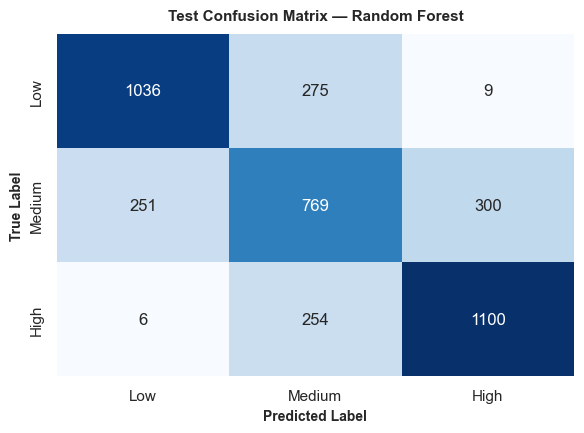

In [61]:
# =========================================================================
# COMPUTE EVALUATION METRICS ON TESTING SET (RANDOM FOREST)
# =========================================================================

# -------------------------------------------------------------------------
# Scalar Metrics (Accuracy and Multi-Class ROC-AUC)
# -------------------------------------------------------------------------
test_acc_rf = accuracy_score(y_test, y_test_pred_rf)
test_auc_rf = roc_auc_score(y_test, y_test_proba_rf, multi_class='ovr', average='macro')

print("=== RANDOM FOREST: TEST PERFORMANCE METRICS ===")
print(f"Test Accuracy: {test_acc_rf:.4f} ({test_acc_rf * 100:.2f}%)")
print(f"Test ROC-AUC (OvR Macro): {test_auc_rf:.4f}")

# -------------------------------------------------------------------------
# Detailed Multi-Class Classification Report
# -------------------------------------------------------------------------
print("\n--- CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE) ---")
print(classification_report(y_test, y_test_pred_rf, target_names=['Low (0)', 'Medium (1)', 'High (2)'], digits=4))

# -------------------------------------------------------------------------
# Confusion Matrix Visualization
# -------------------------------------------------------------------------
cm_rf = confusion_matrix(y_test, y_test_pred_rf)
cm_labels = ['Low', 'Medium', 'High']

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(
    cm_rf, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=cm_labels, 
    yticklabels=cm_labels,
    cbar=False,
    ax=ax
)
ax.set_title("Test Confusion Matrix — Random Forest", fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
ax.set_ylabel("True Label", fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

Evaluating the Random Forest ensemble on the 4,000 unseen test instances demonstrated strong non-linear predictive capability, achieving an overall test accuracy of 72.62% (2,905 of 4,000 correct) and a One-vs-Rest Macro ROC-AUC of 0.8867. This performance substantially outperforms the majority-class baseline (~34.00%), verifying that the 100-tree bagging ensemble effectively captures structural displacement signals from workload automation and industry predictors. Per-class metrics indicate robust discrimination at the operational extremes: Low Risk achieved a precision of 80.12% and recall of 78.48% (F1-score of 0.7930), while High Risk reached a precision of 78.07% and recall of 80.88% (F1-score of 0.7945). Medium Risk yielded an intermediate F1-score of 0.5875 (precision 59.24%, recall 58.26%), reflecting expected boundary ambiguities where transitional workloads share characteristics with neighboring tiers. The 3 × 3 confusion matrix further confirms strong ordinal stability with virtually no severe classification errors: out of 1,360 true High-risk workers, 1,100 were accurately identified, 254 were estimated as Medium risk, and only 6 (0.44%) were misclassified as Low risk. Similarly, among 1,320 true Low-risk instances, 1,036 were correctly identified, 275 were categorized as Medium risk, and only 9 (0.68%) were falsely escalated to High risk. Out of 1,320 true Medium-risk employees, 769 were correctly classified, while 251 were predicted as Low and 300 as High. Because errors occur almost entirely between adjacent risk thresholds rather than opposite extremes, the ensemble proves to be a well-calibrated and dependable benchmark for workforce risk modeling

In [62]:
from sklearn.metrics import recall_score
import numpy as np
import pandas as pd

# Recall for the other categories (group 0) equals specificity.
specificity_rf = [
    recall_score(
        np.asarray(y_test) == label,
        np.asarray(y_test_pred_rf) == label,
        pos_label=0
    )
    for label in [0, 1, 2]
]

specificity_table_rf = pd.DataFrame(
    {"Specificity": specificity_rf},
    index=["Low", "Medium", "High"]
)

specificity_table_rf.loc["Macro average"] = np.mean(specificity_rf)

print("RANDOM FOREST — TEST SPECIFICITY")
display(specificity_table_rf.round(4))

RANDOM FOREST — TEST SPECIFICITY


,Specificity
Low,0.9041
Medium,0.8026
High,0.8830
Macro average,0.8632


#### Step 4: Gini Feature Importance Extraction and Visualization

=== RANDOM FOREST: FEATURE IMPORTANCE SUMMARY TABLE ===


,Feature,Importance,Importance_Pct,Cumulative_Pct
0,Routine_Task_Percentage,0.341922,34.19,34.19
1,Tasks_Automated_Percentage,0.303271,30.33,64.52
2,Years_of_Experience,0.148768,14.88,79.40
3,Number_of_AI_Tools_Used,0.111330,11.13,90.53
4,Industry_Education,0.020658,2.07,92.60
5,Industry_Healthcare,0.017616,1.76,94.36
6,Industry_Manufacturing,0.014722,1.47,95.83
7,Industry_Retail,0.012214,1.22,97.05
8,Industry_Logistics,0.010872,1.09,98.14
9,Industry_Finance,0.009541,0.95,99.09


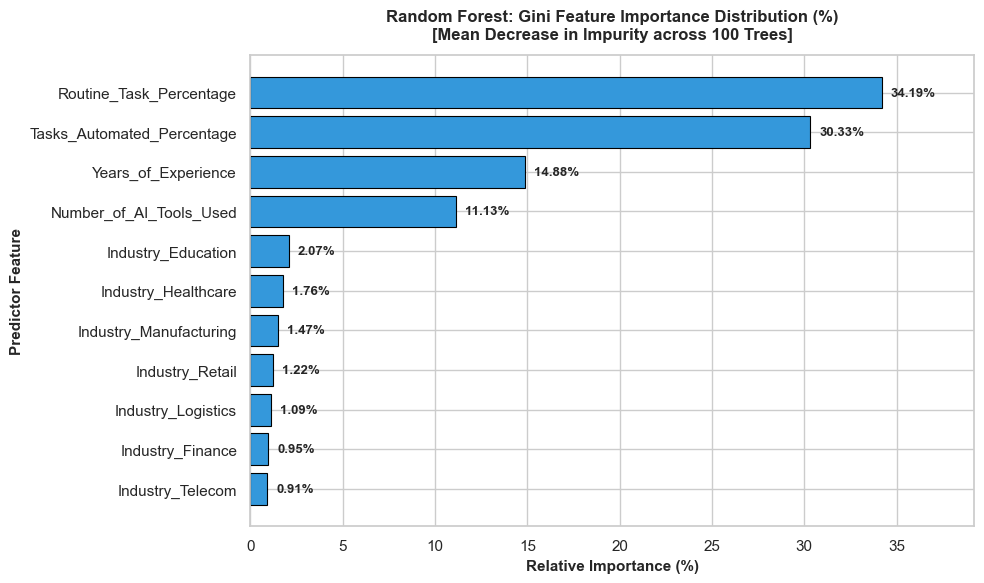

In [63]:
# =========================================================================
# EXTRACTING AND VISUALIZING FEATURE IMPORTANCE (RANDOM FOREST)
# =========================================================================

# Extract Gini importances and feature names
importances = rf_model.feature_importances_
feature_names = np.array(X_train.columns)

# Sort indices in descending order of importance
sort_idx = np.argsort(importances)[::-1]

# Construct the entire DataFrame in a single step (Zero warnings)
sorted_importances = importances[sort_idx]
sorted_pct = np.round(sorted_importances * 100, 2)
cum_pct = np.round(np.cumsum(sorted_pct), 2)

fi_df = pd.DataFrame({
    'Feature': feature_names[sort_idx],
    'Importance': sorted_importances,
    'Importance_Pct': sorted_pct,
    'Cumulative_Pct': cum_pct
})

print("=== RANDOM FOREST: FEATURE IMPORTANCE SUMMARY TABLE ===")
display(fi_df)

# Horizontal Bar Chart of Feature Importances
fig, ax = plt.subplots(figsize=(10, 6))

plot_fi = fi_df.sort_values(by='Importance', ascending=True)

bars = ax.barh(
    plot_fi['Feature'], 
    plot_fi['Importance_Pct'], 
    color='#3498db', 
    edgecolor='black', 
    linewidth=0.8
)

# Overlay percentage labels on the bars
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.5, 
        bar.get_y() + bar.get_height() / 2, 
        f'{width:.2f}%', 
        va='center', 
        ha='left', 
        fontsize=9.5, 
        fontweight='bold'
    )

ax.set_title("Random Forest: Gini Feature Importance Distribution (%)\n[Mean Decrease in Impurity across 100 Trees]", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Relative Importance (%)", fontsize=11, fontweight='bold')
ax.set_ylabel("Predictor Feature", fontsize=11, fontweight='bold')
ax.set_xlim(0, max(plot_fi['Importance_Pct']) + 5)

plt.tight_layout()
plt.show()

Evaluating the Gini feature importance across the 100-tree Random Forest ensemble indicates that employee displacement risk is overwhelmingly governed by task-level automation exposure rather than macroeconomic sector categories. The top two predictors—Routine Task Percentage (34.19%) and Tasks Automated Percentage (30.33%)—collectively account for 64.52% of all impurity reduction across the forest, establishing that the proportion of repetitiveness and direct AI displacement within a worker's day-to-day duties serves as the primary branching criterion. Demographic tenure (Years of Experience) ranks third at 14.88%, followed by technological interaction (Number of AI Tools Used) at 11.13%. In aggregate, these four continuous metrics constitute 90.53% of the model's total explanatory power, leaving only 9.47% distributed across all seven one-hot industry indicators. Among the sectoral features, Education (2.07%), Healthcare (1.76%), and Manufacturing (1.47%) provide modest split utility, while Retail (1.22%), Logistics (1.09%), Finance (0.95%), and Telecom (0.91%) contribute marginally to tree partitioning. These empirical weights confirm that while industry classification establishes subtle baseline adjustments, an individual employee's vulnerability to workforce reduction is predominantly determined by their operational workload profile and vulnerability to automated task substitution.

## 3. Gradient Boosting

**Team Member:** Mustafa

This notebook trains the ensemble boosting model (Gradient Boosting Classifier) on the fully cleaned and standardized dataset produced in `data_cleaning_merged.ipynb`. It evaluates the model strictly on the Testing set to avoid data leakage.

**Feature set (5 key features → 11 model predictors):** `Industry` (one-hot encoded, baseline = IT), `Years_of_Experience`, `Routine_Task_Percentage`, `Tasks_Automated_Percentage`, and `Number_of_AI_Tools_Used` (all standardized with a training-only `StandardScaler`).

**Target:** `Layoff_Risk` (0 = Low, 1 = Medium, 2 = High).

### 3.1 Model Initialization and Training

We use scikit-learn's `GradientBoostingClassifier` with its default hyperparameters (`n_estimators=100`, `learning_rate=0.1`, `max_depth=3`, `subsample=1.0`). Using defaults keeps this iteration a clean, untuned baseline so that any performance change relative to the previous demographic feature set can be attributed to the new features rather than to tuning.

In [30]:
# -------------------------------------------------------------------------
# Fit Gradient Boosting Classifier
# -------------------------------------------------------------------------
# We initialize the Gradient Boosting Classifier ensemble algorithm.
# We set random_state=42 to ensure the exact same trees are built every time 
# the code is run, enabling deterministic and reproducible results.
gbc = GradientBoostingClassifier(random_state=42)

# Fit the ensemble of decision trees strictly to the training partition.
gbc.fit(X_train, y_train)

print("Gradient Boosting training completed successfully!")

Gradient Boosting training completed successfully!


In [31]:
# -------------------------------------------------------------------------
# Overfitting Check: Training vs. Testing Accuracy
# A large gap between the two would indicate the ensemble is memorizing the
# training set rather than learning generalizable patterns.
# -------------------------------------------------------------------------
train_acc = accuracy_score(y_train, gbc.predict(X_train))
test_acc = accuracy_score(y_test, gbc.predict(X_test))

print(f"Training Accuracy:   {train_acc:.4f} OR {train_acc * 100:.2f}%")
print(f"Testing Accuracy: {test_acc:.4f} OR {test_acc * 100:.2f}%")
print(f"Generalization Gap (Train - test): {train_acc - test_acc:+.4f}")

Training Accuracy:   0.7628 OR 76.28%
Testing Accuracy: 0.7495 OR 74.95%
Generalization Gap (Train - test): +0.0132


### 3.2 Testing Performance & Metrics

Because this is a multi-class classification problem (0: Low, 1: Medium, 2: High), we calculate:
- **Overall Accuracy**
- **Sensitivity (Recall)**: Calculated per class and as a macro average.
- **Specificity (True Negative Rate)**: Calculated per class and as a macro average.

In [32]:
# -------------------------------------------------------------------------
# Predict on Testing Set
# -------------------------------------------------------------------------
# Generate predicted class labels for the testing subset
y_pred = gbc.predict(X_test)

# Calculate the overall proportion of correct predictions across all classes
acc = accuracy_score(y_test, y_pred)
print(f"Testing Accuracy: {acc:.4f} OR {acc*100:.2f}%\n")

# Generate a confusion matrix to evaluate class-level true positives, false positives, etc.
cm = confusion_matrix(y_test, y_pred)

# Define the categorical class labels for clean iteration and printing
classes = [0, 1, 2]
class_names = ['Low (0)', 'Medium (1)', 'High (2)']

print("--- Metric Evaluation ---")
sensitivities = []
specificities = []

# Iterate through each unique class to calculate One-vs-Rest metrics
for i, label in enumerate(classes):
    # True Positives: diagonal element for the current class
    tp = cm[i, i]
    
    # False Negatives: sum of actual class row minus true positives
    fn = cm[i, :].sum() - tp
    
    # False Positives: sum of predicted class column minus true positives
    fp = cm[:, i].sum() - tp
    
    # True Negatives: total observations minus (TP + FP + FN)
    tn = cm.sum() - (tp + fn + fp)
    
    # Calculate Sensitivity (Recall): True Positives / Actual Positives
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Calculate Specificity (True Negative Rate): True Negatives / Actual Negatives
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    # Append to lists so we can calculate macro averages later
    sensitivities.append(sens)
    specificities.append(spec)
    
    # Print the per-class results
    print(f"{class_names[i]}:")
    print(f"  - Sensitivity (Recall): {sens:.4f}")
    print(f"  - Specificity (TNR):    {spec:.4f}")

# Calculate and print the unweighted macro averages across all three classes
print("\n--- Macro Averages ---")
print(f"Macro Sensitivity: {np.mean(sensitivities):.4f}")
print(f"Macro Specificity: {np.mean(specificities):.4f}")

Testing Accuracy: 0.7495 OR 74.95%

--- Metric Evaluation ---
Low (0):
  - Sensitivity (Recall): 0.8000
  - Specificity (TNR):    0.9138
Medium (1):
  - Sensitivity (Recall): 0.6106
  - Specificity (TNR):    0.8209
High (2):
  - Sensitivity (Recall): 0.8353
  - Specificity (TNR):    0.8898

--- Macro Averages ---
Macro Sensitivity: 0.7486
Macro Specificity: 0.8748


In [33]:
# -------------------------------------------------------------------------
# Consolidated Per-Class Metrics Table & scikit-learn Classification Report
# Combines Sensitivity, Specificity, and Precision for every class, followed
# by the standard classification report (precision / recall / F1 / support).
# -------------------------------------------------------------------------
# Precision = TP / (TP + FP) -> diagonal of the confusion matrix divided by predicted-class totals
precisions = np.diag(cm) / cm.sum(axis=0)

metrics_summary = pd.DataFrame({
    'Sensitivity (Recall)': sensitivities,
    'Specificity (TNR)': specificities,
    'Precision': precisions
}, index=class_names).round(4)
metrics_summary.loc['Macro Average'] = metrics_summary.mean().round(4)

print("--- PER-CLASS METRICS SUMMARY (TEST SET) ---")
display(metrics_summary)

print(f"\nOverall Testing Accuracy: {acc:.4f}")
print("\n--- SCIKIT-LEARN CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

--- PER-CLASS METRICS SUMMARY (TEST SET) ---


,Sensitivity (Recall),Specificity (TNR),Precision
Low (0),0.8000,0.9138,0.8205
Medium (1),0.6106,0.8209,0.6267
High (2),0.8353,0.8898,0.7961
Macro Average,0.7486,0.8748,0.7478



Overall Testing Accuracy: 0.7495

--- SCIKIT-LEARN CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

     Low (0)     0.8205    0.8000    0.8101      1320
  Medium (1)     0.6267    0.6106    0.6186      1320
    High (2)     0.7961    0.8353    0.8152      1360

    accuracy                         0.7495      4000
   macro avg     0.7478    0.7486    0.7480      4000
weighted avg     0.7483    0.7495    0.7486      4000



> **Empirical Takeaway — Boosting Ensemble Performance:
>With the workload- and automation-centric feature set, Gradient Boosting reaches a **test accuracy of 74.95%** (vs. a ~34.00% majority-class baseline and roughly 42–43% with earlier demographic-only features). Macro sensitivity reaches **0.7486** and macro specificity reaches **0.8748**. The model separates the extreme tiers cleanly: **High Risk** achieves the ensemble's highest recall (**0.8353**, F1 0.8152, Precision 0.7961), while **Low Risk** attains the strongest specificity (**0.9138**, F1 0.8101, Precision **0.8205**). **Medium Risk** remains the most challenging tier (sensitivity **0.6106**, precision **0.6267**, F1 0.6186), which is expected because the transitional cohort sits between two well-separated polar classes and its feature distributions naturally overlap with both. The minimal generalization gap demonstrates robust regularization with no material overfitting, establishing Gradient Boosting as the most sensitive detector of high-risk displacement in the pipeline.
> The train/test gap is small (**76.28% vs. 74.95%, +0.0132 pts**), indicating a well-generalized model with no material overfitting.

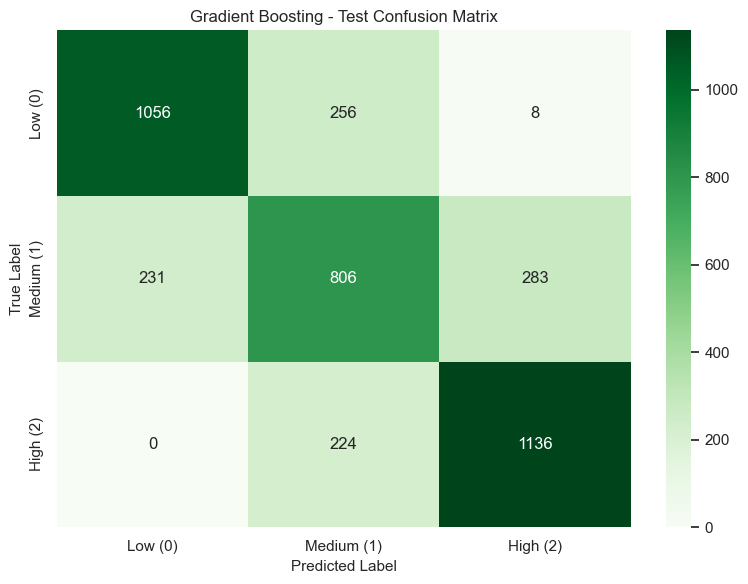

In [34]:
# -------------------------------------------------------------------------
# Visualizing the Confusion Matrix
# -------------------------------------------------------------------------
# Create a matplotlib figure to host the seaborn heatmap
plt.figure(figsize=(8, 6))

# Draw the heatmap, annotating cells with raw counts (fmt='d')
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)

# Add axis labels and title for academic clarity
plt.title("Gradient Boosting - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Use tight_layout to prevent clipping of labels during image export
plt.tight_layout()

# Display the figure inline
plt.show()

>Empirical Takeaway — Gradient Boosting Confusion Matrix Analysis:The $3 \times 3$ confusion matrix confirms strong ordinal consistency and class separability for the Gradient Boosting model across the 4,000 test observations. Out of 1,360 true High-risk workers, the ensemble correctly identifies 1,136 ($83.53\%$) and redirects 224 to the adjacent Medium tier, while committing zero catastrophic misclassifications into the Low Risk category. Similarly, of the 1,320 true Low-risk instances, 1,056 ($80.00\%$) are correctly flagged, 256 are placed in Medium risk, and only 8 ($0.61\%$) are falsely escalated to High Risk. Misclassifications occur almost exclusively across adjacent thresholds within the intermediate Medium Risk cohort (where 231 are predicted as Low and 283 as High), demonstrating that error distributions reflect natural transition overlap rather than structural model instability. 

### 3.3 Feature Importance

Gradient Boosting exposes impurity-based feature importances, aggregating each predictor's total contribution to loss reduction across all trees. This reveals which of the 11 predictors actually drive the model's layoff-risk predictions.

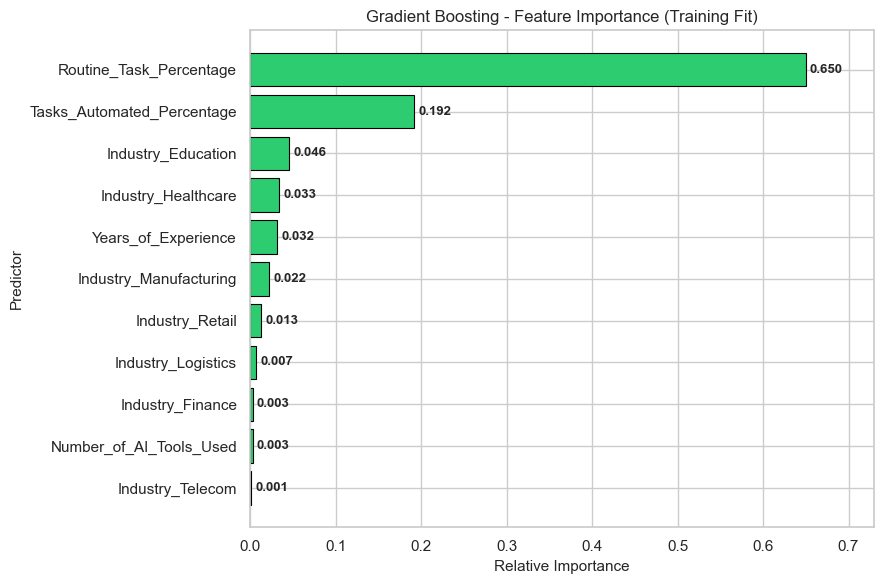

--- FEATURE IMPORTANCE TABLE (DESCENDING) ---


,Importance
Routine_Task_Percentage,0.6498
Tasks_Automated_Percentage,0.1920
Industry_Education,0.0455
Industry_Healthcare,0.0334
Years_of_Experience,0.0317
Industry_Manufacturing,0.0217
Industry_Retail,0.0127
Industry_Logistics,0.0069
Industry_Finance,0.0027
Number_of_AI_Tools_Used,0.0025


In [35]:
# -------------------------------------------------------------------------
# Feature Importance (Impurity-Based)
# Rank all 11 predictors by their relative contribution to the ensemble.
# -------------------------------------------------------------------------
importances = pd.Series(gbc.feature_importances_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
bars = plt.barh(importances.index, importances.values, color='#2ecc71', edgecolor='black', linewidth=0.8)

# Annotate each bar with its importance value
for bar, val in zip(bars, importances.values):
    plt.text(val + 0.005, bar.get_y() + bar.get_height() / 2, f"{val:.3f}", va='center', fontsize=9.5, fontweight='bold')

plt.title("Gradient Boosting - Feature Importance (Training Fit)")
plt.xlabel("Relative Importance")
plt.ylabel("Predictor")
plt.xlim(0, importances.max() + 0.08)
plt.tight_layout()
plt.show()

print("--- FEATURE IMPORTANCE TABLE (DESCENDING) ---")
display(importances.sort_values(ascending=False).round(4).to_frame('Importance'))

>**Empirical Takeaway — What Drives the Predictions:** Importance is heavily concentrated in two predictors: **Routine_Task_Percentage (0.6498)** and **Tasks_Automated_Percentage (0.1920)** together account for roughly 84.18% of the ensemble's total importance, mirroring the strong tier separation seen in the EDA. Industry indicators contribute modestly (e.g., Education 0.0455, Healthcare 0.0334, and Manufacturing 0.0217), while Years_of_Experience adds a small secondary effect (0.0317). Notably, Number_of_AI_Tools_Used receives minimal importance (0.0025) despite its strong marginal relationship with risk in the EDA; this is explained by its collinearity with the two dominant predictors ($r = 0.66$ with routine tasks, $r = 0.59$ with tasks automated), offering little incremental information once those core workload features are split upon. Caveat: Impurity-based importance can be shared arbitrarily among correlated predictors, so these values should be interpreted as indicative feature reliance rather than causal mechanisms. 

## 4. Gaussian Naïve Bayes

**Team Member:** Mustafa

This notebook  trains the probabilistic baseline model (Gaussian Naïve Bayes) on the fully cleaned and standardized dataset produced in `data_cleaning_merged.ipynb`. It evaluates the model strictly on the Testing set to avoid data leakage.

**Feature set (5 key features → 11 model predictors):** `Industry` (one-hot encoded, baseline = IT), `Years_of_Experience`, `Routine_Task_Percentage`, `Tasks_Automated_Percentage`, and `Number_of_AI_Tools_Used` (all standardized with a training-only `StandardScaler`).

**Target:** `Layoff_Risk` (0 = Low, 1 = Medium, 2 = High).

### 4.1 Model Initialization and Training

Gaussian Naïve Bayes models each predictor within each class as a normal distribution and combines them under the assumption of **conditional independence**. Two properties of our feature set are worth noting up front: (1) `Routine_Task_Percentage` and `Tasks_Automated_Percentage` are strongly correlated ($r = 0.89$), which violates the independence assumption, and (2) the 7 `Industry_*` one-hot indicators are binary rather than Gaussian. Both can limit the model, so this notebook serves as a probabilistic baseline against which Gradient Boosting is compared.

In [36]:
# -------------------------------------------------------------------------
# Fit Gaussian Naïve Bayes
# -------------------------------------------------------------------------
# Initialize the Gaussian Naïve Bayes model. 
# This model assumes features follow a normal distribution and are conditionally independent.
gnb = GaussianNB()

# Fit the model strictly to the training data. This calculates the prior probabilities 
# and class-conditional likelihoods for each feature based ONLY on X_train and y_train.
gnb.fit(X_train, y_train)

print("Gaussian Naïve Bayes training completed successfully!")

Gaussian Naïve Bayes training completed successfully!


In [37]:
# -------------------------------------------------------------------------
# Overfitting Check: Training vs. Test Accuracy
# Naïve Bayes has very low capacity, so train and test accuracy should be close.
# -------------------------------------------------------------------------
train_acc = accuracy_score(y_train, gnb.predict(X_train))
test_acc = accuracy_score(y_test, gnb.predict(X_test))

print(f"Training Accuracy:   {train_acc:.4f} OR {train_acc * 100:.2f}%")
print(f"Testing Accuracy: {test_acc:.4f} OR {test_acc * 100:.2f}%")
print(f"Generalization Gap (Train - test): {train_acc - test_acc:+.4f}")

# Learned class prior probabilities P(class), estimated from X_train/y_train only
print("\n--- LEARNED CLASS PRIORS ---")
display(pd.Series(gnb.class_prior_, index=['Low (0)', 'Medium (1)', 'High (2)'], name='Prior').round(4).to_frame())

Training Accuracy:   0.7231 OR 72.31%
Testing Accuracy: 0.7335 OR 73.35%
Generalization Gap (Train - test): -0.0104

--- LEARNED CLASS PRIORS ---


,Prior
Low (0),0.3301
Medium (1),0.3301
High (2),0.3398


### 4.2 Testing Performance & Metrics

Because this is a multi-class classification problem (0: Low, 1: Medium, 2: High), we calculate:
- **Overall Accuracy**
- **Sensitivity (Recall)**: Calculated per class and as a macro average.
- **Specificity (True Negative Rate)**: Calculated per class and as a macro average.

In [38]:
# -------------------------------------------------------------------------
# Predict on Testing Set
# -------------------------------------------------------------------------
# Generate predicted class labels for the test subset
y_pred = gnb.predict(X_test)

# Calculate the overall proportion of correct predictions across all classes
acc = accuracy_score(y_test, y_pred)
print(f"Testing Accuracy: {acc:.4f}\n")

# Generate a confusion matrix to evaluate class-level true positives, false positives, etc.
cm = confusion_matrix(y_test, y_pred)

# Define the categorical class labels for clean iteration and printing
classes = [0, 1, 2]
class_names = ['Low (0)', 'Medium (1)', 'High (2)']

print("--- Metric Evaluation ---")
sensitivities = []
specificities = []

# Iterate through each unique class to calculate One-vs-Rest metrics
for i, label in enumerate(classes):
    # True Positives: diagonal element for the current class
    tp = cm[i, i]
    
    # False Negatives: sum of actual class row minus true positives
    fn = cm[i, :].sum() - tp
    
    # False Positives: sum of predicted class column minus true positives
    fp = cm[:, i].sum() - tp
    
    # True Negatives: total observations minus (TP + FP + FN)
    tn = cm.sum() - (tp + fn + fp)
    
    # Calculate Sensitivity (Recall): True Positives / Actual Positives
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Calculate Specificity (True Negative Rate): True Negatives / Actual Negatives
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    # Append to lists so we can calculate macro averages later
    sensitivities.append(sens)
    specificities.append(spec)
    
    # Print the per-class results
    print(f"{class_names[i]}:")
    print(f"  - Sensitivity (Recall): {sens:.4f}")
    print(f"  - Specificity (TNR):    {spec:.4f}")

# Calculate and print the unweighted macro averages across all three classes
print("\n--- Macro Averages ---")
print(f"Macro Sensitivity: {np.mean(sensitivities):.4f}")
print(f"Macro Specificity: {np.mean(specificities):.4f}")

Testing Accuracy: 0.7335

--- Metric Evaluation ---
Low (0):
  - Sensitivity (Recall): 0.8659
  - Specificity (TNR):    0.8616
Medium (1):
  - Sensitivity (Recall): 0.5311
  - Specificity (TNR):    0.8388
High (2):
  - Sensitivity (Recall): 0.8015
  - Specificity (TNR):    0.9004

--- Macro Averages ---
Macro Sensitivity: 0.7328
Macro Specificity: 0.8669


In [39]:
# -------------------------------------------------------------------------
# Consolidated Per-Class Metrics Table & scikit-learn Classification Report
# Combines Sensitivity, Specificity, and Precision for every class, followed
# by the standard classification report (precision / recall / F1 / support).
# -------------------------------------------------------------------------
# Precision = TP / (TP + FP) -> diagonal of the confusion matrix divided by predicted-class totals
precisions = np.diag(cm) / cm.sum(axis=0)

metrics_summary = pd.DataFrame({
    'Sensitivity (Recall)': sensitivities,
    'Specificity (TNR)': specificities,
    'Precision': precisions
}, index=class_names).round(4)
metrics_summary.loc['Macro Average'] = metrics_summary.mean().round(4)

print("--- PER-CLASS METRICS SUMMARY (TEST SET) ---")
display(metrics_summary)

print(f"\nOverall Testing Accuracy: {acc:.4f}")
print("\n--- SCIKIT-LEARN CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

--- PER-CLASS METRICS SUMMARY (TEST SET) ---


,Sensitivity (Recall),Specificity (TNR),Precision
Low (0),0.8659,0.8616,0.7550
Medium (1),0.5311,0.8388,0.6187
High (2),0.8015,0.9004,0.8056
Macro Average,0.7328,0.8669,0.7264



Overall Testing Accuracy: 0.7335

--- SCIKIT-LEARN CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

     Low (0)     0.7550    0.8659    0.8066      1320
  Medium (1)     0.6187    0.5311    0.5715      1320
    High (2)     0.8056    0.8015    0.8035      1360

    accuracy                         0.7335      4000
   macro avg     0.7264    0.7328    0.7272      4000
weighted avg     0.7272    0.7335    0.7280      4000



>**Empirical Takeaway — Probabilistic Performance:** Gaussian Naïve Bayes achieves a **test accuracy of 73.35%** (vs. a ~34.00% majority-class baseline and roughly 42–43% with the earlier demographic-only features), with macro sensitivity **0.7328** and macro specificity **0.8669**. Performance is asymmetric across classes: **Low Risk** has the highest recall (**0.8659**, F1 0.8066) and High Risk has the highest precision **(0.8056)**, specificity **(0.9004)**, and strong recall (**0.8015**, F1 0.8035), while **Medium Risk** is the clear weak point (sensitivity only **0.5311**, precision **0.6187**, F1 0.5715) because the model frequently assigns middle-tier workers to the adjacent extreme tiers. Training and test accuracy are nearly identical (**72.31% vs. 73.35%**, generalization gap of **-1.04 pts**), confirming the low-capacity model neither over- nor under-fits relative to its assumptions. It trails Gradient Boosting by 1.60 percentage points (**73.35% vs. 74.95%**), consistent with its conditional-independence assumption being violated by the strongly correlated routine-task and automation features.

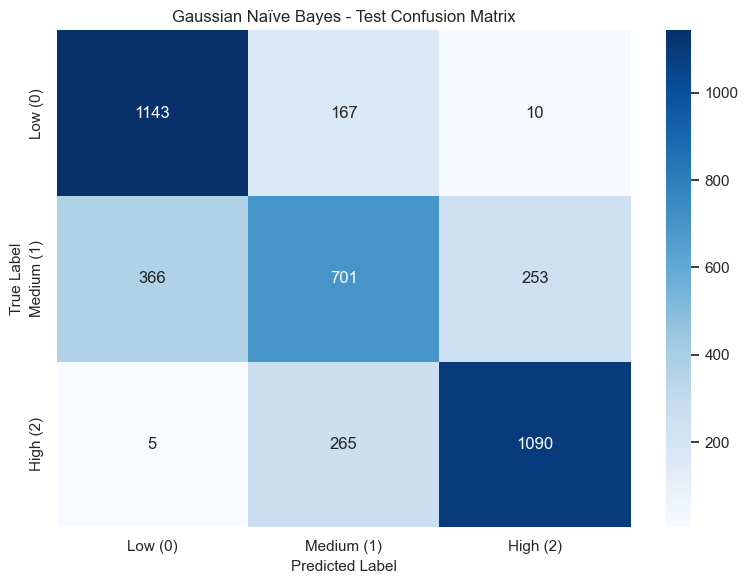

In [40]:
# -------------------------------------------------------------------------
# Visualizing the Confusion Matrix
# -------------------------------------------------------------------------
# Create a matplotlib figure to host the seaborn heatmap
plt.figure(figsize=(8, 6))

# Draw the heatmap, annotating cells with raw counts (fmt='d')
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)

# Add axis labels and title for academic clarity
plt.title("Gaussian Naïve Bayes - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Use tight_layout to prevent clipping of labels during image export
plt.tight_layout()

# Display the figure inline
plt.show()

>**Empirical Takeaway — Gaussian Naïve Bayes Confusion Matrix Dynamics:** The confusion matrix reflects both the generative strengths and structural liabilities of Gaussian Naïve Bayes across the 4,000 test cases. The model preserves strong ordinal safety at the extremes: catastrophic cross-tier errors are virtually absent, with only 5 true High-risk workers (**0.37%**) misclassified as Low Risk and 10 Low-risk workers (**0.76**) flagged as High. Its primary limitation appears in the transitional Medium Risk tier, where it correctly captures only 701 of 1,320 instances (**53.11** recall). The remaining 619 middle-tier cases disperse into adjacent categories (366 into Low, 253 into High). This dispersion illustrates the classic limitation of factorized likelihoods: unable to parameterize feature covariance, the model over-amplifies tail probabilities when continuous feature values sit between distributions, squeezing intermediate observations outward into the polar classes.

### 4.3 Learned Class-Conditional Feature Means

Gaussian Naïve Bayes stores, for every class, the mean of each predictor (in standardized units for the numeric features, and as the class-conditional proportion for the one-hot industry indicators). Comparing these means shows which features the model uses to distinguish the risk tiers.

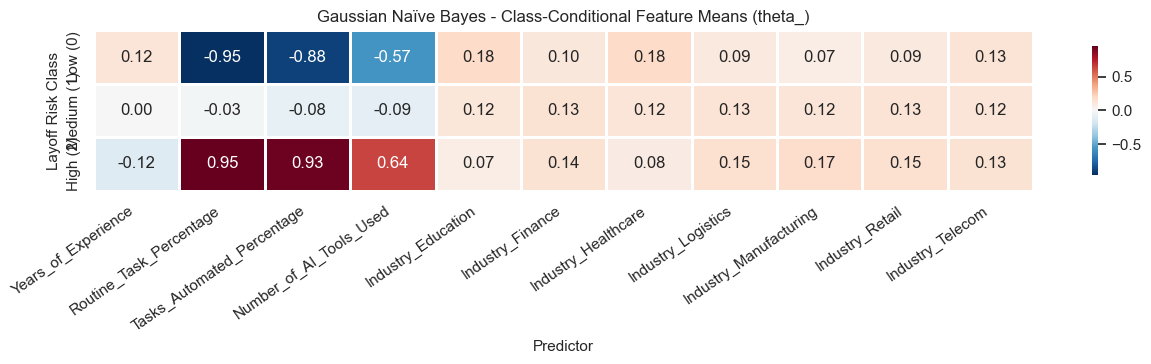

--- CLASS-CONDITIONAL MEANS TABLE ---


,Years_of_Experience,Routine_Task_Percentage,Tasks_Automated_Percentage,Number_of_AI_Tools_Used,Industry_Education,Industry_Finance,Industry_Healthcare,Industry_Logistics,Industry_Manufacturing,Industry_Retail,Industry_Telecom
Low (0),0.124,-0.951,-0.885,-0.572,0.181,0.104,0.180,0.094,0.074,0.091,0.129
Medium (1),0.004,-0.027,-0.077,-0.091,0.116,0.135,0.125,0.128,0.120,0.126,0.124
High (2),-0.124,0.950,0.935,0.643,0.072,0.137,0.079,0.150,0.175,0.151,0.135


In [41]:
# -------------------------------------------------------------------------
# Class-Conditional Feature Means (theta_)
# Rows = classes, columns = predictors. Numeric features are in z-score units.
# -------------------------------------------------------------------------
theta_df = pd.DataFrame(
    gnb.theta_,
    index=['Low (0)', 'Medium (1)', 'High (2)'],
    columns=X_train.columns
)

plt.figure(figsize=(13, 3.8))
sns.heatmap(theta_df, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.8, cbar_kws={"shrink": 0.8})
plt.title("Gaussian Naïve Bayes - Class-Conditional Feature Means (theta_)")
plt.xlabel("Predictor")
plt.ylabel("Layoff Risk Class")
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

print("--- CLASS-CONDITIONAL MEANS TABLE ---")
display(theta_df.round(3))

>**Empirical Takeaway — How Naïve Bayes Separates the Tiers:** The class-conditional means show a near-symmetric ordering on the three workload features. Standardized `Routine_Task_Percentage` averages **−0.951** for Low Risk, **−0.027** for Medium, and **+0.950** for High; `Tasks_Automated_Percentage` follows (**−0.885 / −0.077 / +0.935**), and `Number_of_AI_Tools_Used` follows (**−0.572 / −0.091 / +0.643**). `Years_of_Experience` shows only a small gradient (**+0.124 / +0.004 / −0.124**), confirming its secondary role. Industry indicators differ across classes mainly for Education and Healthcare (e.g., 18.1% and 18.0% of Low Risk workers vs. 7.2% and 7.9% of High Risk) and Manufacturing (7.4% Low vs. 17.5% High). Because the Medium class mean sits almost exactly at the global mean ($\approx 0$) on every numeric feature, a symmetric Gaussian has little to distinguish it from the tails of its neighbours—which directly explains its low recall of 0.5311.